# 03 Model selection

QuantCell does not prescribe a single classifier. The best model depends on the tissue, the marker panel and the imaging data, so this notebook compares candidate classifiers on your own rule-based annotated cells and reports which one performs best.

Each candidate is scored by **macro average precision (AP)** with stratified k-fold cross-validation on the **training split only**. The test split that `process_data()` holds out is not touched, so it remains available for the final evaluation.

Run `02a_initialization_qupath.ipynb` first. Use the winning model in `04_annotation.ipynb`.

In [1]:
import os, warnings, time
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt

os.chdir('../Quantcell')
from quantcell import quantcell_project
warnings.filterwarnings('ignore')

from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import RidgeClassifier, LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import average_precision_score
from lightgbm import LGBMClassifier   # pip install lightgbm==4.6.0

Parameters, as in the other notebooks.
 - `hyperparameter_dir`: folder with tuned hyperparameters for each model (`<ModelName>_best_params_macro.joblib`). The files shipped in `../hyperparameters` were tuned on the bone marrow data in the paper. Set to `None` to compare models with default settings.
 - `n_splits`: number of cross-validation folds (the paper uses 10; 5 is faster for a first pass).
 - `n_jobs`: CPU threads per model (-1 = all).

In [2]:
annotations_path = '../marker_combos_062525_updated_verified.json'
base_dir = '../Output'
project_name = 'QuantCellPaperO3'
hyperparameter_dir = '../hyperparameters'
n_splits = 5
n_jobs = -1

In [3]:
project = quantcell_project()
project.initialize(base_path=base_dir, project_name=project_name)
project.process_data()
print('training cells:', project.X_train.shape[0], ' features:', project.X_train.shape[1], ' cell types:', len(project.target_encoder.classes_))

Initializing project QuantCellPaperO3 at ../Output
training cells: 19092  features: 500  cell types: 21


Candidate classifiers. Remove entries to save time, or add any scikit-learn compatible classifier. Models without `predict_proba` (linear SVC, ridge) are scored on their decision function.

In [4]:
def params(name):
    path = None if hyperparameter_dir is None else f'{hyperparameter_dir}/{name}_best_params_macro.joblib'
    return joblib.load(path) if path and os.path.exists(path) else {}

seed = project.random_seed
candidates = {
    'LightGBM':              LGBMClassifier(**params('LGBMClassifier'), n_jobs=n_jobs, random_state=seed, verbose=-1),
    'Random forest':         RandomForestClassifier(**params('RandomForestClassifier'), n_jobs=n_jobs, random_state=seed),
    'Multilayer perceptron': MLPClassifier(**params('MLPClassifier'), random_state=seed),
    'Extra trees':           ExtraTreesClassifier(**params('ExtraTreesClassifier'), n_jobs=n_jobs, random_state=seed),
    'Logistic regression':   LogisticRegression(**params('LogisticRegression'), n_jobs=n_jobs, random_state=seed),
    'Nearest neighbors':     KNeighborsClassifier(**params('KNeighborsClassifier'), n_jobs=n_jobs),
    'Decision tree':         DecisionTreeClassifier(**params('DecisionTreeClassifier'), random_state=seed),
    'Linear SVC':            OneVsRestClassifier(LinearSVC(random_state=seed, dual='auto',
                                 **{k.replace('estimator__', ''): v for k, v in params('LinearSVC').items()}), n_jobs=n_jobs),
    'Ridge classifier':      RidgeClassifier(**params('RidgeClassifier'), random_state=seed),
    'Gaussian naive Bayes':  GaussianNB(**params('GaussianNB')),
}

Score every candidate with the same cross-validation folds. `cv_fit_pred` fits a fresh copy of the model in each fold and returns the held-out labels and predicted probabilities.

In [5]:
results = {}
for name, model in candidates.items():
    project.set_clf(model)
    t = time.time()
    y_true, y_pred, y_score = project.cv_fit_pred(name=name, n_splits=n_splits)
    ap = [average_precision_score(y_true[i], y_score[i], average='macro') for i in range(n_splits)]
    results[name] = {'macro AP': np.mean(ap), 'SD': np.std(ap), 'seconds per fold': (time.time() - t) / n_splits}
    print(f"{name:<24} macro AP {np.mean(ap):.3f} ± {np.std(ap):.3f}")

summary = pd.DataFrame(results).T.sort_values('macro AP', ascending=False)
summary

LightGBM: 100%|██████████| 5/5 [25:10<00:00, 302.13s/it]


LightGBM                 macro AP 0.937 ± 0.014


Random forest: 100%|██████████| 5/5 [00:30<00:00,  6.10s/it]


Random forest            macro AP 0.903 ± 0.006


Multilayer perceptron: 100%|██████████| 5/5 [04:55<00:00, 59.15s/it]


...

Ridge classifier: 100%|██████████| 5/5 [00:02<00:00,  1.74it/s]


Ridge classifier         macro AP 0.557 ± 0.010


Gaussian naive Bayes: 100%|██████████| 5/5 [00:04<00:00,  1.17it/s]


Gaussian naive Bayes     macro AP 0.450 ± 0.008


,macro AP,SD,seconds per fold
LightGBM,0.936967,0.014293,302.155417
Random forest,0.902759,0.006445,6.117802
Multilayer perceptron,0.866593,0.006946,59.181456
Extra trees,0.850520,0.013731,5.017282
Logistic regression,0.797322,0.012178,19.729345
Decision tree,0.694153,0.015904,15.786762
Nearest neighbors,0.684263,0.006912,10.674938
Linear SVC,0.634248,0.013960,11.993979
Ridge classifier,0.556970,0.009706,0.609336
Gaussian naive Bayes,0.450014,0.008412,0.902949


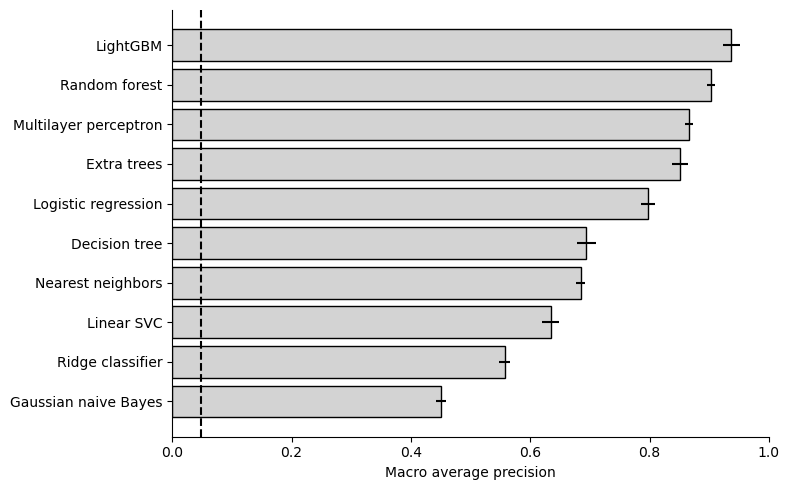

Best model: LightGBM


In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(summary.index[::-1], summary['macro AP'][::-1], xerr=summary['SD'][::-1], color='lightgray', edgecolor='black')
ax.axvline(1 / len(project.target_encoder.classes_), color='black', ls='--', lw=1.5)   # random-prediction baseline
ax.set_xlim(0, 1); ax.set_xlabel('Macro average precision'); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()
print('Best model:', summary.index[0])

### Optional: tune hyperparameters on your data

The shipped hyperparameters were tuned on the bone marrow data. To tune for your own dataset, search a grid with the same macro AP score and cross-validation on the training split, then save the result to `hyperparameter_dir` so the comparison above and `04_annotation.ipynb` pick it up. The grid below is deliberately small; the grids used in the paper are listed in Table EV2.

In [7]:
from sklearn.experimental import enable_halving_search_cv  # noqa: F401
from sklearn.model_selection import HalvingGridSearchCV, StratifiedKFold

def macro_ap_scorer(estimator, X, y):
    """Macro average precision over the cell types present in y (robust to the small subsamples used by halving search)."""
    S = np.asarray(estimator.predict_proba(X) if hasattr(estimator, 'predict_proba') else estimator.decision_function(X))
    classes = np.asarray(estimator.classes_)
    keep = [i for i, c in enumerate(classes) if np.any(y == c)]
    return float(np.mean([average_precision_score((y == classes[i]).astype(int), S[:, i]) for i in keep])) if keep else np.nan

tune = False   # set True to run
if tune:
    grid = {'learning_rate': [0.02, 0.05, 0.1], 'num_leaves': [31, 63], 'n_estimators': [100, 300]}
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    search = HalvingGridSearchCV(LGBMClassifier(random_state=seed, verbose=-1, n_jobs=1), grid, factor=3,
                                 cv=cv, scoring=macro_ap_scorer, n_jobs=n_jobs, random_state=seed)
    search.fit(project.X_train, project.y_train)
    print(search.best_params_, round(search.best_score_, 3))
    # joblib.dump(search.best_params_, f'{hyperparameter_dir}/LGBMClassifier_best_params_macro.joblib')